In [1]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch_geometric.nn import GCNConv
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

BASE = Path("D:/adaptive_federated_gnn")
GRAPH_PATH = BASE / "data/processed/edge_graph.pt"
CLIENT_PATH = BASE / "outputs/day10/federated_clients.pt"
OUT = BASE / "outputs/day16"
OUT.mkdir(parents=True, exist_ok=True)

torch.manual_seed(42)
np.random.seed(42)

graph = torch.load(GRAPH_PATH, map_location="cpu", weights_only=False)
old_clients = torch.load(CLIENT_PATH, map_location="cpu", weights_only=False)

edge_index = graph["edge_index"].long()
feature_key = "edge_attr" if "edge_attr" in graph else "edge_features"
label_key = "edge_label" if "edge_label" in graph else "edge_labels"

edge_features = graph[feature_key].float()
edge_labels = graph[label_key].long().view(-1)

# Keep the original Day 10 training/test separation.
train_indices = np.unique(np.concatenate([
    old_clients[name]["local_edge_indices"].cpu().numpy()
    if torch.is_tensor(old_clients[name]["local_edge_indices"])
    else np.asarray(old_clients[name]["local_edge_indices"])
    for name in ["client_1", "client_2", "client_3"]
])).astype(np.int64)

all_labels = edge_labels.numpy()
classes, counts = np.unique(all_labels[train_indices], return_counts=True)

assert len(classes) == 2, "Expected binary labels."
benign_label = classes[np.argmin(counts)]
attack_label = classes[np.argmax(counts)]

rng = np.random.default_rng(42)
attack_idx = train_indices[all_labels[train_indices] == attack_label].copy()
benign_idx = train_indices[all_labels[train_indices] == benign_label].copy()
rng.shuffle(attack_idx)
rng.shuffle(benign_idx)

# Equal-sized clients with deliberately different attack proportions.
sizes = [len(x) for x in np.array_split(train_indices, 3)]
attack_quotas = [
    round(sizes[0] * 0.60),
    round(sizes[1] * 0.90),
    0
]
attack_quotas[2] = len(attack_idx) - sum(attack_quotas)

assert 0 <= attack_quotas[2] <= sizes[2], (
    "Chosen proportions are infeasible for this dataset."
)

non_iid_clients = {}
a_start = b_start = 0

for i, name in enumerate(["client_1", "client_2", "client_3"]):
    n_attack = attack_quotas[i]
    n_benign = sizes[i] - n_attack

    selected = np.concatenate([
        attack_idx[a_start:a_start + n_attack],
        benign_idx[b_start:b_start + n_benign]
    ])
    a_start += n_attack
    b_start += n_benign
    rng.shuffle(selected)

    idx = torch.tensor(selected, dtype=torch.long)

    non_iid_clients[name] = {
        "edge_index": edge_index,
        "edge_features": edge_features[idx],
        "edge_labels": edge_labels[idx],
        "local_edge_indices": idx
    }

distribution_rows = []
for name, data in non_iid_clients.items():
    labels = data["edge_labels"].numpy()
    distribution_rows.append({
        "Client": name,
        "Total Edges": len(labels),
        "Benign Edges": int((labels == benign_label).sum()),
        "Attack Edges": int((labels == attack_label).sum()),
        "Attack Percentage": round(
            100 * (labels == attack_label).mean(), 2
        )
    })

distribution = pd.DataFrame(distribution_rows)
display(distribution)

torch.save(non_iid_clients, OUT / "non_iid_clients.pt")
distribution.to_csv(OUT / "non_iid_client_distribution.csv", index=False)

print("Training edges:", len(train_indices))
print("Held-out test edges:", len(edge_labels) - len(train_indices))
print("Non-IID clients prepared.")

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Client,Total Edges,Benign Edges,Attack Edges,Attack Percentage
0,client_1,66756,26702,40054,60.00
1,client_2,66755,6675,60080,90.00
2,client_3,66755,55726,11029,16.52


Training edges: 200266
Held-out test edges: 85829
Non-IID clients prepared.


In [2]:
num_nodes = int(edge_index.max().item()) + 1
edge_feature_size = edge_features.shape[1]

class EdgeGCN(nn.Module):
    def __init__(self, num_nodes, edge_feature_size,
                 embedding_size=16, hidden_size=32):
        super().__init__()

        self.node_embeddings = nn.Embedding(num_nodes, embedding_size)
        self.conv1 = GCNConv(embedding_size, hidden_size)
        self.conv2 = GCNConv(hidden_size, hidden_size)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2 + edge_feature_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, edge_index, edge_features):
        node_ids = torch.arange(
            self.node_embeddings.num_embeddings,
            device=edge_index.device
        )

        x = self.node_embeddings(node_ids)
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))

        source = x[edge_index[0]]
        destination = x[edge_index[1]]

        combined = torch.cat(
            [source, destination, edge_features], dim=1
        )
        return self.classifier(combined)

initial_model = EdgeGCN(num_nodes, edge_feature_size)
initial_state = copy.deepcopy(initial_model.state_dict())

print("Model initialized.")
print("Number of graph nodes:", num_nodes)
print("Edge feature count:", edge_feature_size)

Model initialized.
Number of graph nodes: 4404
Edge feature count: 67


In [3]:
local_models = {}
local_rows = []

for name, data in non_iid_clients.items():
    print(f"\nTraining {name}...")

    local_model = EdgeGCN(num_nodes, edge_feature_size)
    local_model.load_state_dict(copy.deepcopy(initial_state))

    optimizer = torch.optim.Adam(local_model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    local_edge_indices = data["local_edge_indices"].long()
    client_edge_index = edge_index[:, local_edge_indices]
    client_x = data["edge_features"].float()
    client_y = data["edge_labels"].long()

    local_model.train()

    # Two epochs to keep CPU training manageable.
    for epoch in range(2):
        optimizer.zero_grad()

        logits = local_model(client_edge_index, client_x)
        loss = criterion(logits, client_y)

        loss.backward()
        optimizer.step()

        print(f"{name} | Epoch {epoch + 1}/2 | Loss: {loss.item():.4f}")

    local_model.eval()
    with torch.no_grad():
        predictions = local_model(
            client_edge_index, client_x
        ).argmax(dim=1)

    local_rows.append({
        "Client": name,
        "Training Edges": len(client_y),
        "Final Training Loss": float(loss.item()),
        "Training Accuracy": accuracy_score(
            client_y.numpy(), predictions.numpy()
        )
    })

    local_models[name] = local_model
    torch.save(
        local_model.state_dict(),
        OUT / f"{name}_local_model.pt"
    )

local_metrics = pd.DataFrame(local_rows)
display(local_metrics)
local_metrics.to_csv(OUT / "local_training_metrics.csv", index=False)

print("All local models trained and saved.")


Training client_1...
client_1 | Epoch 1/2 | Loss: 0.7149
client_1 | Epoch 2/2 | Loss: 0.6707

Training client_2...
client_2 | Epoch 1/2 | Loss: 0.7001
client_2 | Epoch 2/2 | Loss: 0.6455

Training client_3...
client_3 | Epoch 1/2 | Loss: 0.7217
client_3 | Epoch 2/2 | Loss: 0.6519


,Client,Training Edges,Final Training Loss,Training Accuracy
0,client_1,66756,0.670668,0.787854
1,client_2,66755,0.645494,0.946880
2,client_3,66755,0.651934,0.814621


All local models trained and saved.


In [4]:
client_sizes = {
    name: len(data["edge_labels"])
    for name, data in non_iid_clients.items()
}
total_size = sum(client_sizes.values())

client_weights = {
    name: size / total_size
    for name, size in client_sizes.items()
}

global_state = copy.deepcopy(local_models["client_1"].state_dict())

for key in global_state:
    global_state[key] = torch.zeros_like(global_state[key])

for name, model in local_models.items():
    state = model.state_dict()
    weight = client_weights[name]

    for key in global_state:
        global_state[key] += state[key] * weight

global_model = EdgeGCN(num_nodes, edge_feature_size)
global_model.load_state_dict(global_state)

torch.save(global_model.state_dict(), OUT / "non_iid_global_model.pt")

weights_df = pd.DataFrame([
    {
        "Client": name,
        "Training Edges": client_sizes[name],
        "FedAvg Weight": client_weights[name]
    }
    for name in non_iid_clients
])
display(weights_df)
weights_df.to_csv(OUT / "fedavg_client_weights.csv", index=False)

print("Global model saved:", OUT / "non_iid_global_model.pt")

,Client,Training Edges,FedAvg Weight
0,client_1,66756,0.333337
1,client_2,66755,0.333332
2,client_3,66755,0.333332


Global model saved: D:\adaptive_federated_gnn\outputs\day16\non_iid_global_model.pt


In [5]:
train_set = set(train_indices.tolist())
test_indices = np.array([
    i for i in range(len(edge_labels))
    if i not in train_set
], dtype=np.int64)

assert len(test_indices) > 0, "No held-out test edges found."

test_tensor = torch.tensor(test_indices, dtype=torch.long)
test_y = edge_labels[test_tensor].numpy()

global_model.eval()
with torch.no_grad():
    # Full graph topology is used for inference; only held-out
    # edge predictions are evaluated.
    all_logits = global_model(edge_index, edge_features)
    test_logits = all_logits[test_tensor]
    test_predictions = test_logits.argmax(dim=1).numpy()
    test_probabilities = torch.softmax(test_logits, dim=1)[:, 1].numpy()

metrics = {
    "Accuracy": accuracy_score(test_y, test_predictions),
    "Precision": precision_score(
        test_y, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        test_y, test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        test_y, test_predictions, zero_division=0
    )
}

metrics_df = pd.DataFrame([metrics])
display(metrics_df)
metrics_df.to_csv(OUT / "non_iid_global_test_metrics.csv", index=False)

cm = confusion_matrix(test_y, test_predictions, labels=[0, 1])
pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
).to_csv(OUT / "non_iid_confusion_matrix.csv")

report = classification_report(
    test_y, test_predictions, output_dict=True, zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    OUT / "non_iid_classification_report.csv"
)

pd.DataFrame({
    "Edge Index": test_indices,
    "Actual Label": test_y,
    "Predicted Label": test_predictions,
    "Attack Probability": test_probabilities
}).to_csv(OUT / "non_iid_test_predictions.csv", index=False)

print("Held-out evaluation complete.")

,Accuracy,Precision,Recall,F1 Score
0,0.58563,0.652498,0.542285,0.592308


Held-out evaluation complete.


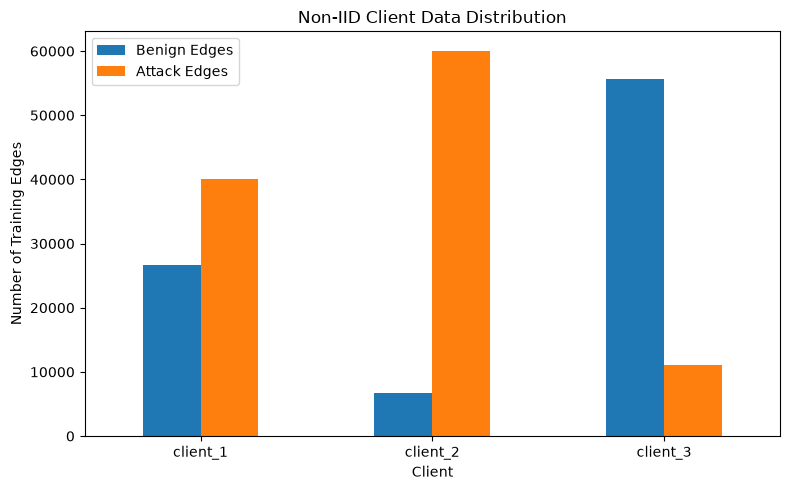

In [6]:
plot_data = distribution.set_index("Client")[
    ["Benign Edges", "Attack Edges"]
]

plot_data.plot(kind="bar", figsize=(8, 5))
plt.title("Non-IID Client Data Distribution")
plt.xlabel("Client")
plt.ylabel("Number of Training Edges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "non_iid_distribution.png", dpi=150)
plt.show()

In [7]:
print("DAY 16 OUTPUT FILES")

for path in sorted(OUT.iterdir()):
    print(path.name)

print("\nGlobal test metrics:")
display(pd.read_csv(OUT / "non_iid_global_test_metrics.csv"))

print("\nClient distribution:")
display(pd.read_csv(OUT / "non_iid_client_distribution.csv"))

DAY 16 OUTPUT FILES
client_1_local_model.pt
client_2_local_model.pt
client_3_local_model.pt
fedavg_client_weights.csv
local_training_metrics.csv
non_iid_classification_report.csv
non_iid_client_distribution.csv
non_iid_clients.pt
non_iid_confusion_matrix.csv
non_iid_distribution.png
non_iid_global_model.pt
non_iid_global_test_metrics.csv
non_iid_test_predictions.csv

Global test metrics:


,Accuracy,Precision,Recall,F1 Score
0,0.58563,0.652498,0.542285,0.592308



Client distribution:


,Client,Total Edges,Benign Edges,Attack Edges,Attack Percentage
0,client_1,66756,26702,40054,60.00
1,client_2,66755,6675,60080,90.00
2,client_3,66755,55726,11029,16.52
